# Component 3 — Leakage-Safe Feature Engineering

This notebook converts the integrated Western Province fisheries–environment observations into a monthly modelling panel. Each row represents an observed **calendar month × 0.10° spatial cell × species × gear** combination. The target is median catch weight per record in month `t`; predictors use information available no later than month `t-1`.

## Modelling decisions and safeguards

- **Forecast horizon:** one calendar month ahead.
- **Target:** `log1p` of monthly median catch weight per record. Effort is unavailable, so this is a catch-availability proxy rather than CPUE.
- **Localization:** 0.10° cells (approximately 11 km north–south) provide a reproducible provisional unit for the Western Province study area.
- **No current-month leakage:** contemporaneous catch, environmental values, totals and record counts are not predictors.
- **Exact calendar lags:** lag 1 means the immediately preceding calendar month—not merely the previous observed row.
- **No fabricated zeros:** an unobserved group-month is missing/unknown, not zero catch. No interpolation, backfill, encoding or imputation occurs here.
- **Environmental candidates:** lags 1–6 are generated. The earlier lag rankings are exploratory; final selection must happen using training data only.
- **Next stage boundary:** chronological splitting, train-only preprocessing, model fitting and evaluation belong in later notebooks.

In [1]:
import importlib.util, subprocess, sys
packages={'pandas':'pandas>=2.0,<3','numpy':'numpy>=1.24,<3','pyarrow':'pyarrow>=14,<22','matplotlib':'matplotlib>=3.7,<4'}
missing=[spec for module,spec in packages.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable,'-m','pip','install',*missing])
print('Feature-engineering dependencies are available.')

Feature-engineering dependencies are available.


In [2]:
from __future__ import annotations
import json, os, re, sys, unicodedata
from pathlib import Path
import matplotlib
if 'IPython' not in sys.modules: matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
try:
    from IPython.display import display
except ImportError:
    display=print
pd.set_option('display.max_columns',120); plt.style.use('seaborn-v0_8-whitegrid')
COLORS={'target':'#4e79a7','history':'#8f63b8','chl':'#59a14f','sst':'#f28e2b'}
SPATIAL_CELL_DEGREES=0.10
CATCH_LAGS=list(range(1,7)); ENVIRONMENT_LAGS=list(range(1,7))

## 1. Locate and validate the integrated input

In [3]:
def find_component_root(start:Path)->Path:
    for anchor in [start.resolve(),*start.resolve().parents]:
        for candidate in [anchor,anchor/'component - 3',anchor/'J26-DS-350'/'component - 3']:
            if (candidate/'Notebooks').is_dir() and (candidate/'src').is_dir(): return candidate.resolve()
    raise FileNotFoundError('Component 3 repository root was not found.')
IN_COLAB='google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive'); ROOT=Path('/content/drive/MyDrive/FishGuard-C3')
else: ROOT=find_component_root(Path.cwd())
PROCESSED_DIR=Path(os.getenv('FISHGUARD_C3_PROCESSED_DIR',str(ROOT/'data'/'processed'))).resolve()
EVIDENCE_DIR=Path(os.getenv('FISHGUARD_C3_FEATURE_OUTPUT',str(ROOT/'outputs'/'audit'/'feature_engineering'))).resolve()
FIGURE_DIR=Path(os.getenv('FISHGUARD_C3_FEATURE_FIGURES',str(ROOT/'outputs'/'figures'/'feature_engineering'))).resolve()
for directory in [PROCESSED_DIR,EVIDENCE_DIR,FIGURE_DIR]: directory.mkdir(parents=True,exist_ok=True)
DATA_PATH=PROCESSED_DIR/'fisheries_environment_integrated_complete.parquet'
OUTPUT_PATH=PROCESSED_DIR/'monthly_model_features.parquet'
if not DATA_PATH.is_file(): raise FileNotFoundError(f'Missing {DATA_PATH}. Run 03_data_integration.ipynb first.')
df=pd.read_parquet(DATA_PATH)
required={'event_date','latitude','longitude','species','gear','catch_weight_kg','chlorophyll_a_mg_m3','sea_surface_temperature_c','environment_complete','source_row_number'}
missing=required-set(df.columns)
if missing: raise KeyError(f'Missing integrated fields: {sorted(missing)}')
assert df.environment_complete.fillna(False).all(), 'Input contains incomplete environmental matches.'
df['event_date']=pd.to_datetime(df.event_date,errors='coerce')
for column in ['latitude','longitude','catch_weight_kg','chlorophyll_a_mg_m3','sea_surface_temperature_c']:
    df[column]=pd.to_numeric(df[column],errors='coerce')
analysis=df.dropna(subset=['event_date','latitude','longitude','species','gear','catch_weight_kg','chlorophyll_a_mg_m3','sea_surface_temperature_c']).copy()
analysis=analysis.loc[(analysis.catch_weight_kg>=0)&(analysis.chlorophyll_a_mg_m3>=0)]
print('Runtime:','Google Colab' if IN_COLAB else 'Local Windows'); print('Eligible rows:',f'{len(analysis):,}')
print('Coverage:',analysis.event_date.min().date(),'to',analysis.event_date.max().date())

Mounted at /content/drive
Runtime: Google Colab
Eligible rows: 26,081
Coverage: 2017-10-16 to 2024-12-30


## 2. Standardize analysis labels and define the spatial–temporal unit

In [4]:
def clean_category_text(value):
    if pd.isna(value): return ''
    value=unicodedata.normalize('NFKD',str(value)).encode('ascii','ignore').decode()
    value=re.sub(r'(?i)_x000d_',' ',value)
    return re.sub(r'\s+',' ',value).strip().lower()
def category_key(value): return re.sub(r'[^a-z0-9]+','',clean_category_text(value))
SPECIES_ALIASES={'skipjacktuna':'skipjack tuna','skipjack':'skipjack tuna','yellowfintuna':'yellowfin tuna','yellofintuna':'yellowfin tuna','yellowfin':'yellowfin tuna','sailfish':'sailfish','swordfish':'swordfish','swardfish':'swordfish','bigeyetuna':'bigeye tuna','frigatetuna':'frigate tuna','blackmarlin':'black marlin','bluemarlin':'blue marlin','spanishmackerel':'spanish mackerel','spanishmackrel':'spanish mackerel','mobulaspp':'mobula spp'}
GEAR_ALIASES={'gillnet':'gillnet','gillnets':'gillnet','gillent':'gillnet','ringnet':'ring net','longline':'longline'}
def canonical_label(value,aliases):
    cleaned=clean_category_text(value)
    return 'unknown' if not cleaned else aliases.get(category_key(value),cleaned)
analysis['species_model']=analysis.species.map(lambda value:canonical_label(value,SPECIES_ALIASES))
analysis['gear_model']=analysis.gear.map(lambda value:canonical_label(value,GEAR_ALIASES))
analysis['month_start']=analysis.event_date.dt.to_period('M').dt.to_timestamp()
analysis['cell_lat_min']=np.floor(analysis.latitude/SPATIAL_CELL_DEGREES)*SPATIAL_CELL_DEGREES
analysis['cell_lon_min']=np.floor(analysis.longitude/SPATIAL_CELL_DEGREES)*SPATIAL_CELL_DEGREES
analysis['cell_lat_center']=analysis.cell_lat_min+SPATIAL_CELL_DEGREES/2
analysis['cell_lon_center']=analysis.cell_lon_min+SPATIAL_CELL_DEGREES/2
analysis['spatial_cell_id']=analysis.cell_lat_min.map(lambda x:f'{x:.2f}')+'_'+analysis.cell_lon_min.map(lambda x:f'{x:.2f}')
GROUP_KEYS=['spatial_cell_id','species_model','gear_model']
print('Spatial cells:',analysis.spatial_cell_id.nunique(),'Species:',analysis.species_model.nunique(),'Gears:',analysis.gear_model.nunique())

Spatial cells: 65 Species: 65 Gears: 3


## 3. Construct the observed monthly target panel

Only combinations with an observed fisheries record receive a target row. Total catch and record count are retained strictly as diagnostics or possible sample weights—not predictors.

In [5]:
panel=(analysis.groupby(['month_start',*GROUP_KEYS],observed=True).agg(
    target_median_catch_weight_kg=('catch_weight_kg','median'),
    diagnostic_total_catch_weight_kg=('catch_weight_kg','sum'),
    diagnostic_record_count=('source_row_number','size'),
    cell_lat_center=('cell_lat_center','first'),
    cell_lon_center=('cell_lon_center','first')).reset_index())
panel['target_log1p_median_catch']=np.log1p(panel.target_median_catch_weight_kg.clip(lower=0))
panel['forecast_horizon_months']=1
assert not panel.duplicated(['month_start',*GROUP_KEYS]).any()
print('Observed modelling rows:',f'{len(panel):,}')
display(panel.head())

Observed modelling rows: 10,050


,month_start,spatial_cell_id,species_model,gear_model,target_median_catch_weight_kg,diagnostic_total_catch_weight_kg,diagnostic_record_count,cell_lat_center,cell_lon_center,target_log1p_median_catch,forecast_horizon_months
0,2017-10-01,6.70_79.40,swordfish,gillnet,180.0,540.0,3,6.75,79.45,5.198497,1
1,2017-10-01,6.70_79.40,yellowfin tuna,gillnet,32.5,195.0,6,6.75,79.45,3.511545,1
2,2017-12-01,6.90_79.60,yellowfin tuna,gillnet,15.0,15.0,1,6.95,79.65,2.772589,1
3,2018-01-01,6.20_79.30,indian scad (linna),ring net,3000.0,3000.0,1,6.25,79.35,8.006701,1
4,2018-01-01,6.20_79.30,skipjack tuna,ring net,600.0,600.0,1,6.25,79.35,6.398595,1


## 4. Add exact-calendar historical catch features

Four history levels reduce sparsity: exact cell–species–gear, species, spatial cell and study-wide. Every merge is date-aware; if month `t-k` was not observed, the lag stays missing.

In [6]:
def merge_exact_lags(base,lookup,keys,date_column,value_columns,prefix,lags):
    result=base.copy()
    assert not lookup.duplicated([date_column,*keys]).any(), f'Duplicate lookup keys for {prefix}'
    for lag in lags:
        shifted=lookup[[date_column,*keys,*value_columns]].copy()
        shifted[date_column]=shifted[date_column]+pd.DateOffset(months=lag)
        shifted=shifted.rename(columns={column:f'{prefix}_{column}_lag_{lag}' for column in value_columns})
        result=result.merge(shifted,on=[date_column,*keys],how='left',validate='m:1')
    return result
catch_value=['median_catch_weight_kg']
group_history=panel[['month_start',*GROUP_KEYS,'target_median_catch_weight_kg']].rename(columns={'target_median_catch_weight_kg':'median_catch_weight_kg'})
species_history=(analysis.groupby(['month_start','species_model'],observed=True).catch_weight_kg.median().rename('median_catch_weight_kg').reset_index())
cell_history=(analysis.groupby(['month_start','spatial_cell_id'],observed=True).catch_weight_kg.median().rename('median_catch_weight_kg').reset_index())
global_history=(analysis.groupby('month_start',observed=True).catch_weight_kg.median().rename('median_catch_weight_kg').reset_index())
features=merge_exact_lags(panel,group_history,GROUP_KEYS,'month_start',catch_value,'group',CATCH_LAGS)
features=merge_exact_lags(features,species_history,['species_model'],'month_start',catch_value,'species',CATCH_LAGS)
features=merge_exact_lags(features,cell_history,['spatial_cell_id'],'month_start',catch_value,'cell',CATCH_LAGS)
features=merge_exact_lags(features,global_history,[],'month_start',catch_value,'global',CATCH_LAGS)
for prefix in ['group','species','cell','global']:
    lag_columns=[f'{prefix}_median_catch_weight_kg_lag_{lag}' for lag in CATCH_LAGS]
    features[f'{prefix}_catch_history_months_available']=features[lag_columns].notna().sum(axis=1).astype('int8')
    features[f'{prefix}_catch_rolling_mean_3m']=features[lag_columns[:3]].mean(axis=1,skipna=True)
    features[f'{prefix}_catch_rolling_mean_6m']=features[lag_columns].mean(axis=1,skipna=True)
print('Historical catch features added:',len(features.columns)-len(panel.columns))

Historical catch features added: 36


## 5. Add lagged environmental features

In [7]:
environment_values=['median_chlorophyll_a_mg_m3','median_sst_c']
cell_environment=(analysis.groupby(['month_start','spatial_cell_id'],observed=True).agg(
    median_chlorophyll_a_mg_m3=('chlorophyll_a_mg_m3','median'),
    median_sst_c=('sea_surface_temperature_c','median')).reset_index())
global_environment=(analysis.groupby('month_start',observed=True).agg(
    median_chlorophyll_a_mg_m3=('chlorophyll_a_mg_m3','median'),
    median_sst_c=('sea_surface_temperature_c','median')).reset_index())
features=merge_exact_lags(features,cell_environment,['spatial_cell_id'],'month_start',environment_values,'cell_env',ENVIRONMENT_LAGS)
features=merge_exact_lags(features,global_environment,[],'month_start',environment_values,'global_env',ENVIRONMENT_LAGS)
for prefix in ['cell_env','global_env']:
    chl=[f'{prefix}_median_chlorophyll_a_mg_m3_lag_{lag}' for lag in ENVIRONMENT_LAGS]
    sst=[f'{prefix}_median_sst_c_lag_{lag}' for lag in ENVIRONMENT_LAGS]
    complete_lag_months=pd.concat([(features[chl[index]].notna()&features[sst[index]].notna()).rename(f'lag_{lag}') for index,lag in enumerate(ENVIRONMENT_LAGS)],axis=1)
    features[f'{prefix}_months_available']=complete_lag_months.sum(axis=1).astype('int8')
    features[f'{prefix}_chlorophyll_rolling_mean_3m']=features[chl[:3]].mean(axis=1,skipna=True)
    features[f'{prefix}_sst_rolling_mean_3m']=features[sst[:3]].mean(axis=1,skipna=True)
    features[f'{prefix}_chlorophyll_change_1m']=features[chl[0]]-features[chl[1]]
    features[f'{prefix}_sst_change_1m']=features[sst[0]]-features[sst[1]]
print('Total columns after environmental lags:',len(features.columns))

Total columns after environmental lags: 81


## 6. Add known-in-advance calendar features

In [8]:
features['year']=features.month_start.dt.year.astype('int16')
features['month']=features.month_start.dt.month.astype('int8')
features['month_sin']=np.sin(2*np.pi*features.month/12)
features['month_cos']=np.cos(2*np.pi*features.month/12)
origin=features.month_start.min()
features['months_since_start']=((features.month_start.dt.year-origin.year)*12+(features.month_start.dt.month-origin.month)).astype('int16')
def climate_season(month):
    if month in (12,1,2): return 'northeast_monsoon'
    if month in (3,4): return 'first_intermonsoon'
    if month in (5,6,7,8,9): return 'southwest_monsoon'
    return 'second_intermonsoon'
features['climate_season']=features.month.map(climate_season).astype('string')
features['eligible_minimum_history']=(features.global_catch_history_months_available>=1)&features.global_env_median_chlorophyll_a_mg_m3_lag_1.notna()&features.global_env_median_sst_c_lag_1.notna()
features=features.sort_values(['month_start',*GROUP_KEYS]).reset_index(drop=True)
display(features[['month_start',*GROUP_KEYS,'target_log1p_median_catch','eligible_minimum_history']].head())

,month_start,spatial_cell_id,species_model,gear_model,target_log1p_median_catch,eligible_minimum_history
0,2017-10-01,6.70_79.40,swordfish,gillnet,5.198497,False
1,2017-10-01,6.70_79.40,yellowfin tuna,gillnet,3.511545,False
2,2017-12-01,6.90_79.60,yellowfin tuna,gillnet,2.772589,False
3,2018-01-01,6.20_79.30,indian scad (linna),ring net,8.006701,True
4,2018-01-01,6.20_79.30,skipjack tuna,ring net,6.398595,True


## 7. Leakage audit and feature dictionary

In [9]:
TARGET_COLUMNS=['target_median_catch_weight_kg','target_log1p_median_catch']
DIAGNOSTIC_COLUMNS=['diagnostic_total_catch_weight_kg','diagnostic_record_count']
IDENTIFIER_COLUMNS=['month_start','spatial_cell_id']
ELIGIBILITY_COLUMNS=['eligible_minimum_history']
NON_PREDICTOR_COLUMNS=set(TARGET_COLUMNS+DIAGNOSTIC_COLUMNS+IDENTIFIER_COLUMNS+ELIGIBILITY_COLUMNS+['forecast_horizon_months'])
PREDICTOR_COLUMNS=[column for column in features.columns if column not in NON_PREDICTOR_COLUMNS]
lag_predictors=[column for column in PREDICTOR_COLUMNS if '_lag_' in column]
leakage_checks=pd.DataFrame([
 {'check':'unique panel key','passed':not features.duplicated(['month_start',*GROUP_KEYS]).any(),'detail':'One target row per month × cell × species × gear'},
 {'check':'no lag zero predictors','passed':not any(re.search(r'_lag_0(?:$|_)',column) for column in PREDICTOR_COLUMNS),'detail':'All history starts at t-1'},
 {'check':'target excluded from predictors','passed':not set(TARGET_COLUMNS)&set(PREDICTOR_COLUMNS),'detail':str(TARGET_COLUMNS)},
 {'check':'current-month diagnostics excluded','passed':not set(DIAGNOSTIC_COLUMNS)&set(PREDICTOR_COLUMNS),'detail':str(DIAGNOSTIC_COLUMNS)},
 {'check':'forecast horizon fixed','passed':features.forecast_horizon_months.eq(1).all(),'detail':'One calendar month'},
 {'check':'lag naming uses positive months','passed':all(int(re.search(r'_lag_(\d+)$',column).group(1))>=1 for column in lag_predictors),'detail':f'{len(lag_predictors)} lagged predictor columns'}])
assert leakage_checks.passed.all(), leakage_checks.loc[~leakage_checks.passed].to_dict('records')
def feature_role(column):
    if column in TARGET_COLUMNS: return 'target'
    if column in DIAGNOSTIC_COLUMNS: return 'diagnostic_or_weight_not_predictor'
    if column in IDENTIFIER_COLUMNS: return 'identifier_or_grouping'
    if column in ELIGIBILITY_COLUMNS: return 'eligibility_filter_not_predictor'
    if column=='forecast_horizon_months': return 'metadata'
    return 'candidate_predictor'
dictionary=pd.DataFrame({'column':features.columns})
dictionary['dtype']=dictionary.column.map(lambda column:str(features[column].dtype))
dictionary['role']=dictionary.column.map(feature_role)
dictionary['missing_count']=dictionary.column.map(lambda column:int(features[column].isna().sum()))
dictionary['missing_percent']=dictionary.missing_count/len(features)*100
dictionary['availability']=dictionary.column.map(lambda column:'month t outcome; never a predictor' if column in TARGET_COLUMNS+DIAGNOSTIC_COLUMNS else ('known before month t' if feature_role(column)=='candidate_predictor' else 'structural'))
leakage_checks.to_csv(EVIDENCE_DIR/'leakage_checks.csv',index=False)
dictionary.to_csv(EVIDENCE_DIR/'feature_dictionary.csv',index=False)
display(leakage_checks); display(dictionary.head(20))

,check,passed,detail
0,unique panel key,True,One target row per month × cell × species × gear
1,no lag zero predictors,True,All history starts at t-1
2,target excluded from predictors,True,"['target_median_catch_weight_kg', 'target_log1..."
3,current-month diagnostics excluded,True,"['diagnostic_total_catch_weight_kg', 'diagnost..."
4,forecast horizon fixed,True,One calendar month
5,lag naming uses positive months,True,48 lagged predictor columns


,column,dtype,role,missing_count,missing_percent,availability
0,month_start,datetime64[ns],identifier_or_grouping,0,0.000000,structural
1,spatial_cell_id,object,identifier_or_grouping,0,0.000000,structural
2,species_model,object,candidate_predictor,0,0.000000,known before month t
3,gear_model,object,candidate_predictor,0,0.000000,known before month t
4,target_median_catch_weight_kg,Float64,target,0,0.000000,month t outcome; never a predictor
5,diagnostic_total_catch_weight_kg,Float64,diagnostic_or_weight_not_predictor,0,0.000000,month t outcome; never a predictor
6,diagnostic_record_count,int64,diagnostic_or_weight_not_predictor,0,0.000000,month t outcome; never a predictor
7,cell_lat_center,Float64,candidate_predictor,0,0.000000,known before month t
8,cell_lon_center,Float64,candidate_predictor,0,0.000000,known before month t
9,target_log1p_median_catch,Float64,target,0,0.000000,month t outcome; never a predictor


## 8. Save modelling artifact and audit summaries

In [10]:
features.to_parquet(OUTPUT_PATH,index=False)
monthly_coverage=(features.groupby('month_start').agg(modelling_rows=('target_log1p_median_catch','size'),eligible_rows=('eligible_minimum_history','sum'),spatial_cells=('spatial_cell_id','nunique'),species=('species_model','nunique'),gears=('gear_model','nunique')).reset_index())
missingness=(dictionary.loc[dictionary.role=='candidate_predictor',['column','missing_count','missing_percent']].sort_values('missing_percent',ascending=False))
overview=pd.DataFrame([
 {'metric':'input_integrated_rows','value':len(analysis)},
 {'metric':'monthly_modelling_rows','value':len(features)},
 {'metric':'eligible_minimum_history_rows','value':int(features.eligible_minimum_history.sum())},
 {'metric':'calendar_months','value':features.month_start.nunique()},
 {'metric':'spatial_cells','value':features.spatial_cell_id.nunique()},
 {'metric':'species_categories','value':features.species_model.nunique()},
 {'metric':'gear_categories','value':features.gear_model.nunique()},
 {'metric':'candidate_predictors','value':len(PREDICTOR_COLUMNS)},
 {'metric':'forecast_horizon_months','value':1},
 {'metric':'spatial_cell_degrees','value':SPATIAL_CELL_DEGREES}])
overview.to_csv(EVIDENCE_DIR/'feature_engineering_overview.csv',index=False)
monthly_coverage.to_csv(EVIDENCE_DIR/'monthly_feature_coverage.csv',index=False)
missingness.to_csv(EVIDENCE_DIR/'feature_missingness.csv',index=False)
display(overview); print('Saved:',OUTPUT_PATH)

,metric,value
0,input_integrated_rows,26081.0
1,monthly_modelling_rows,10050.0
2,eligible_minimum_history_rows,9930.0
3,calendar_months,83.0
4,spatial_cells,65.0
5,species_categories,65.0
6,gear_categories,3.0
7,candidate_predictors,80.0
8,forecast_horizon_months,1.0
9,spatial_cell_degrees,0.1


Saved: /content/drive/MyDrive/FishGuard-C3/data/processed/monthly_model_features.parquet


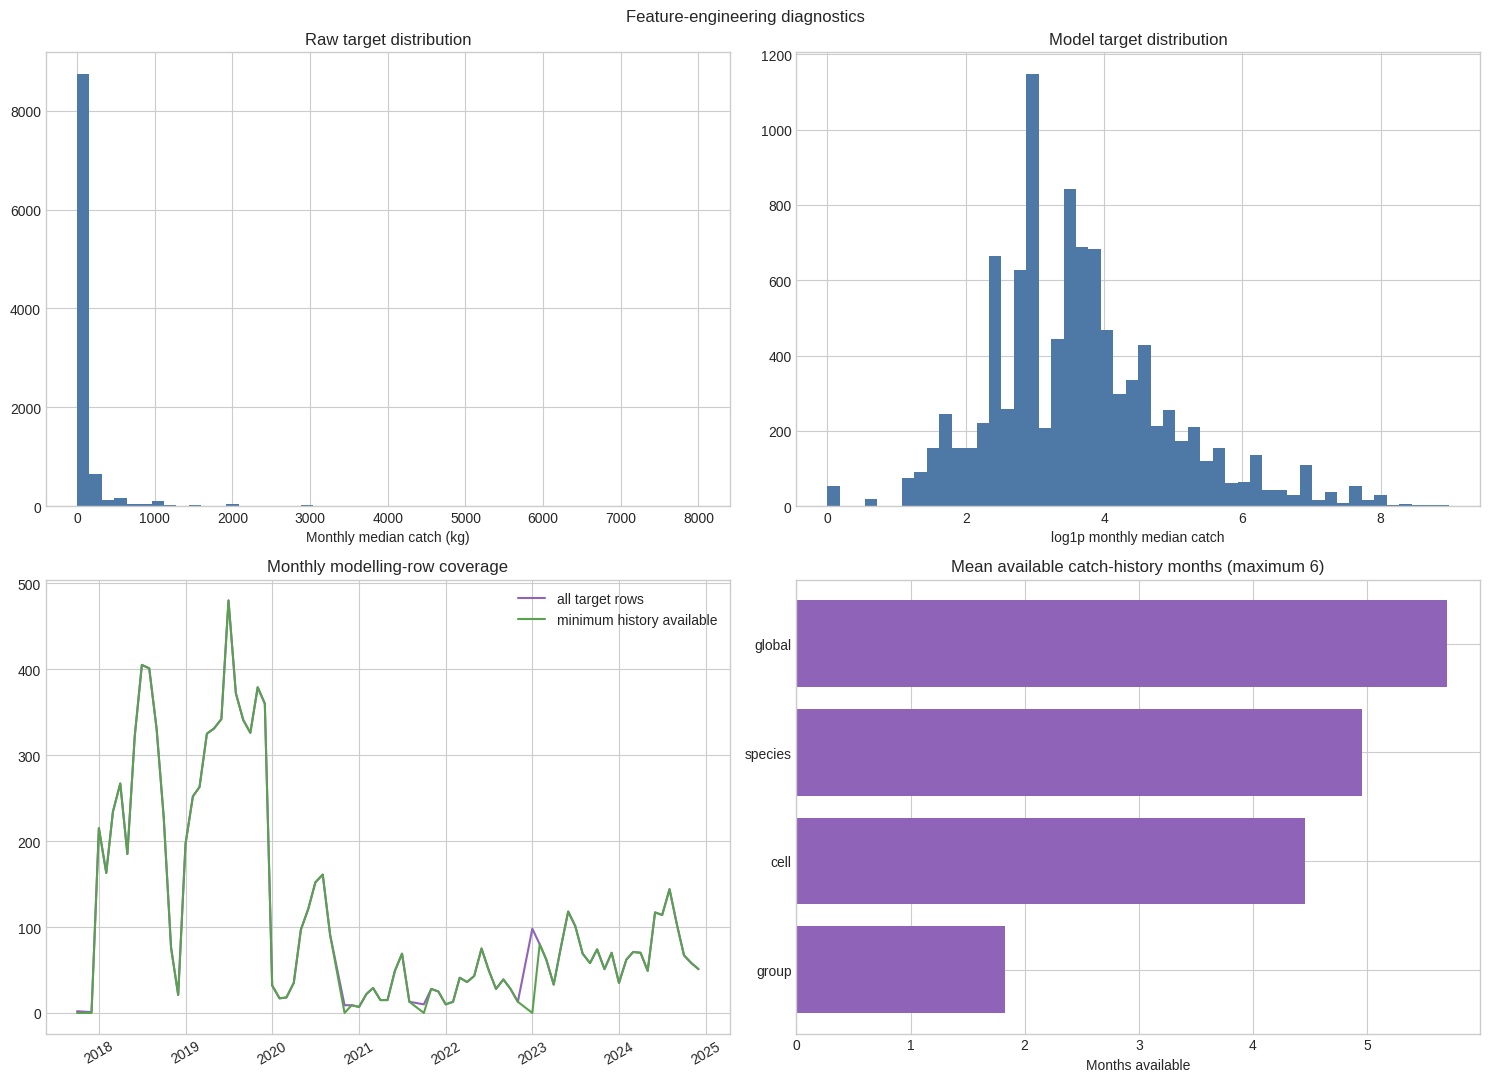

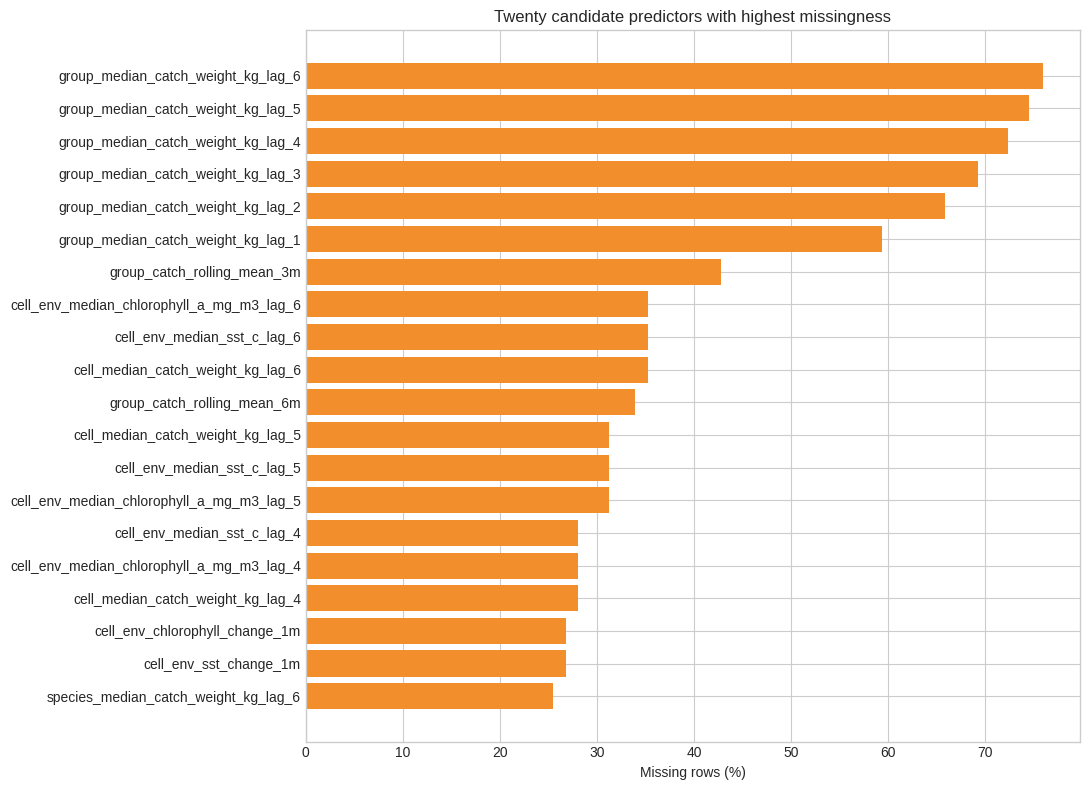

In [11]:
fig,axes=plt.subplots(2,2,figsize=(15,11))
axes[0,0].hist(features.target_median_catch_weight_kg,bins=50,color=COLORS['target']); axes[0,0].set_title('Raw target distribution'); axes[0,0].set_xlabel('Monthly median catch (kg)')
axes[0,1].hist(features.target_log1p_median_catch,bins=50,color=COLORS['target']); axes[0,1].set_title('Model target distribution'); axes[0,1].set_xlabel('log1p monthly median catch')
axes[1,0].plot(monthly_coverage.month_start,monthly_coverage.modelling_rows,label='all target rows',color=COLORS['history']); axes[1,0].plot(monthly_coverage.month_start,monthly_coverage.eligible_rows,label='minimum history available',color=COLORS['chl']); axes[1,0].set_title('Monthly modelling-row coverage'); axes[1,0].legend(); axes[1,0].tick_params(axis='x',rotation=30)
availability=features[['group_catch_history_months_available','species_catch_history_months_available','cell_catch_history_months_available','global_catch_history_months_available']].mean().sort_values()
axes[1,1].barh(availability.index.str.replace('_catch_history_months_available',''),availability.values,color=COLORS['history']); axes[1,1].set_title('Mean available catch-history months (maximum 6)'); axes[1,1].set_xlabel('Months available')
fig.suptitle('Feature-engineering diagnostics'); fig.tight_layout(); fig.savefig(FIGURE_DIR/'feature_engineering_diagnostics.png',dpi=200,bbox_inches='tight'); plt.show()
top_missing=missingness.head(20).sort_values('missing_percent')
fig,ax=plt.subplots(figsize=(11,8)); ax.barh(top_missing.column,top_missing.missing_percent,color=COLORS['sst']); ax.set_xlabel('Missing rows (%)'); ax.set_title('Twenty candidate predictors with highest missingness'); fig.tight_layout(); fig.savefig(FIGURE_DIR/'feature_missingness.png',dpi=200,bbox_inches='tight'); plt.show()

## 9. Save viva findings and reproducibility manifest

In [12]:
findings=pd.DataFrame([
 {'finding':'Forecast unit','result':'One calendar month × 0.10° spatial cell × species × gear'},
 {'finding':'Forecast horizon','result':'One month ahead'},
 {'finding':'Prediction target','result':'log1p monthly median catch weight per record; catch-availability proxy, not CPUE'},
 {'finding':'Effort limitation','result':'Reliable comparable effort is unavailable; current-month total catch and record count are diagnostics, not predictors'},
 {'finding':'Environmental lag policy','result':'Generate lags 1–6; select or regularize using training data only'},
 {'finding':'Missing group-month policy','result':'Missing/unknown, never automatically zero, interpolated or backfilled'},
 {'finding':'Leakage audit','result':f'{int(leakage_checks.passed.sum())} of {len(leakage_checks)} checks passed'},
 {'finding':'Model-ready rows with minimum history','result':f"{int(features.eligible_minimum_history.sum()):,} of {len(features):,}"},
 {'finding':'Next required stage','result':'Chronological split design and modelling EDA before train-only preprocessing and model fitting'}])
findings.to_csv(EVIDENCE_DIR/'feature_engineering_findings.csv',index=False)
manifest={'created_utc':pd.Timestamp.now(tz='UTC').isoformat(),'runtime':'Google Colab' if IN_COLAB else 'Local Windows','input':DATA_PATH.name,'output':OUTPUT_PATH.name,'input_rows':len(analysis),'output_rows':len(features),'scope':'Western Province study data','temporal_unit':'calendar month','forecast_horizon_months':1,'panel_unit':'month × 0.10-degree cell × species × gear','target':'target_log1p_median_catch','target_interpretation':'catch availability per observed record; not CPUE','catch_lags_months':CATCH_LAGS,'environment_lags_months':ENVIRONMENT_LAGS,'lag_policy':'exact prior calendar months only','missing_policy':'retain missing; no zero-fill, interpolation, backfill or imputation','source_artifact_modified':False,'chronological_split_created':False,'figures':sorted(p.name for p in FIGURE_DIR.glob('*.png')),'evidence':sorted(p.name for p in EVIDENCE_DIR.glob('*.csv'))}
with (EVIDENCE_DIR/'feature_engineering_manifest.json').open('w',encoding='utf-8') as f: json.dump(manifest,f,indent=2)
display(findings); print('Evidence:',EVIDENCE_DIR); print('Figures:',FIGURE_DIR)

,finding,result
0,Forecast unit,One calendar month × 0.10° spatial cell × spec...
1,Forecast horizon,One month ahead
2,Prediction target,log1p monthly median catch weight per record; ...
3,Effort limitation,Reliable comparable effort is unavailable; cur...
4,Environmental lag policy,Generate lags 1–6; select or regularize using ...
5,Missing group-month policy,"Missing/unknown, never automatically zero, int..."
6,Leakage audit,6 of 6 checks passed
7,Model-ready rows with minimum history,"9,930 of 10,050"
8,Next required stage,Chronological split design and modelling EDA b...


Evidence: /content/drive/MyDrive/FishGuard-C3/outputs/audit/feature_engineering
Figures: /content/drive/MyDrive/FishGuard-C3/outputs/figures/feature_engineering


## Viva interpretation

The modelling table is observational and represents catch availability conditional on recorded fishing activity. A row is not evidence that no fish were available in unobserved cells or months. All historical features are backward-looking by exact calendar time. The final model must use chronological validation, and categorical encoding, missing-value treatment, scaling and any feature selection must be learned from training data only.